In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [3]:
df=pd.read_excel(r'C:\Users\yashi\OneDrive\Documents\E-commerce_retail_dataset.xlsx')

In [4]:
df.head()

,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,...,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship
0,ORD-03903,2024-08-15 00:00:00,CUST32603,Aarav Mehta,39.0,Other,Central,Raipur,Groceries,Sugar,...,346.32,NaN,4043.14,289.18,56.04,Debit Card,NaN,True,Returned,7.0
1,ORD-02198,2022-08-16 00:00:00,CUST07881,Sanjay Verma,28.0,Male,West,Mumbai,Beauty,Sunscreen,...,858.66,0.08,9147.31,5355.56,64.49,Debit Card,5.0,False,Delivered,2.0
2,ORD-01348,2021-08-29 00:00:00,CUST49296,Pooja Sharma,41.0,Other,West,Surat,Furniture,Sofa,...,25941.32,0.14,110156.97,36956.51,67.65,Debit Card,4.0,False,Delivered,5.0
3,ORD-02076,2022-07-05 00:00:00,CUST05587,Priya Reddy,29.0,Other,West,Ahmedabad,Furniture,Bed Frame,...,22071.92,0.17,262066.11,66644.99,54.47,EMI,3.0,False,Delivered,4.0
4,ORD-00287,2020-05-07 00:00:00,CUST58035,Ritu Sharma,9.0,Male,Central,Nagpur,Groceries,Cooking Oil,...,320.06,0.31,323.95,31.38,48.81,Net Banking,4.0,False,Pending,4.0


In [5]:
# To convert the date format to proper datetime format
df['order_date']=pd.to_datetime(df['order_date'])

In [6]:
# Replacing the NULL value into the 'NO Return' value
df['customer_satisfaction']=df['customer_satisfaction'].replace('NULL','No_Return')

In [8]:
# Create a new column to calculation 'Profit_Margin_Percentage'
df['profit_margin_pct']=(df['profit']/df['sales_amount'])*100
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1987 entries, 0 to 1986
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               1987 non-null   str           
 1   order_date             1987 non-null   datetime64[us]
 2   customer_id            1987 non-null   str           
 3   customer_name          1987 non-null   str           
 4   age                    1920 non-null   float64       
 5   gender                 1987 non-null   str           
 6   region                 1987 non-null   str           
 7   city                   1987 non-null   str           
 8   product_category       1987 non-null   str           
 9   product_name           1987 non-null   str           
 10  quantity               1934 non-null   float64       
 11  unit_price             1987 non-null   float64       
 12  discount_pct           1926 non-null   float64       
 13  sales_amount  

In [9]:
df.head()

,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,...,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_flag,order_status,days_to_ship,profit_margin_pct
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39.0,Other,Central,Raipur,Groceries,Sugar,...,NaN,4043.14,289.18,56.04,Debit Card,NaN,True,Returned,7.0,7.152362
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28.0,Male,West,Mumbai,Beauty,Sunscreen,...,0.08,9147.31,5355.56,64.49,Debit Card,5.0,False,Delivered,2.0,58.547923
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41.0,Other,West,Surat,Furniture,Sofa,...,0.14,110156.97,36956.51,67.65,Debit Card,4.0,False,Delivered,5.0,33.548953
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29.0,Other,West,Ahmedabad,Furniture,Bed Frame,...,0.17,262066.11,66644.99,54.47,EMI,3.0,False,Delivered,4.0,25.430602
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,9.0,Male,Central,Nagpur,Groceries,Cooking Oil,...,0.31,323.95,31.38,48.81,Net Banking,4.0,False,Pending,4.0,9.686680


In [11]:
# Group by function for product category and calculate total metrics
category_analysis=df.groupby('product_category').agg(total_sales=('sales_amount','sum'),total_profit=('profit','sum'))
average_margin=('profit_margin_pct','mean')
print(category_analysis)

                  total_sales  total_profit
product_category                           
Beauty             1791809.57     829635.53
Books              2052008.71     781605.38
Clothing           5699098.48    2112214.20
Electronics       64222678.56    7803102.27
Furniture         25711747.81    7207922.80
Groceries           548204.60      42061.61
Sports            19154737.23    4215135.47


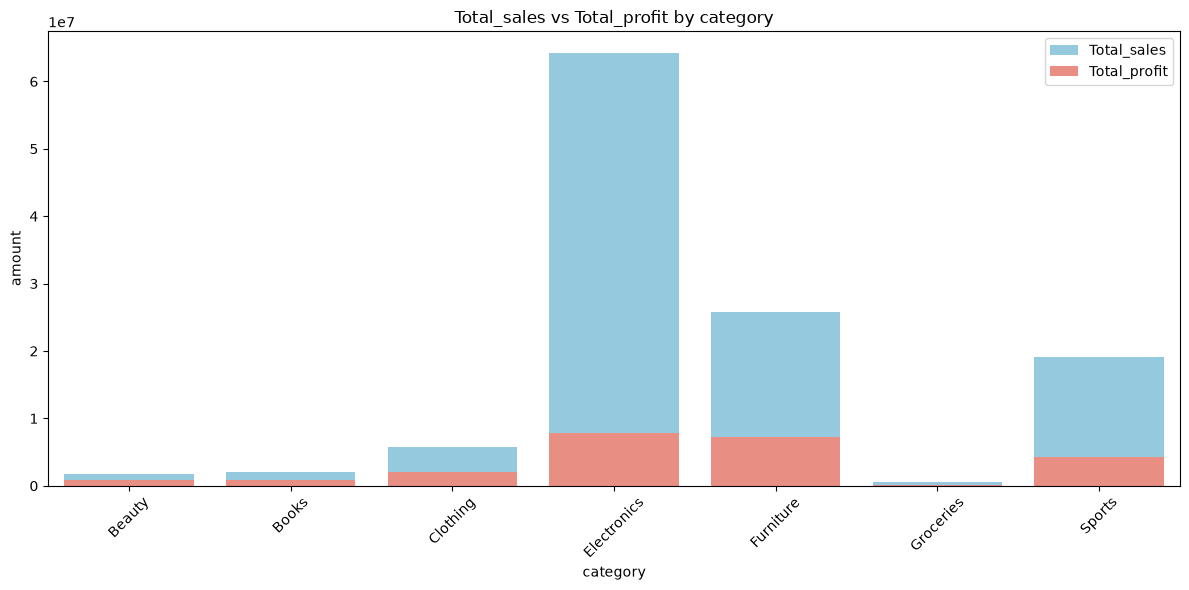

In [12]:
# Plotting sales and profit by category
plt.figure(figsize=(12,6))
sb.barplot(x=category_analysis.index,y='total_sales',data=category_analysis,color='skyblue',label='Total_sales')
sb.barplot(x=category_analysis.index,y='total_profit',data=category_analysis,color='salmon',label='Total_profit')
plt.title('Total_sales vs Total_profit by category')
plt.xlabel('category')
plt.ylabel('amount')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

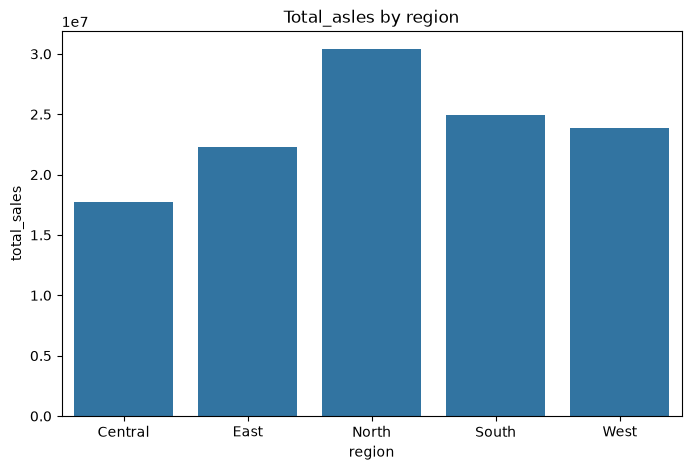

In [15]:
# Sales distribution by region
region_sales=df.groupby('region')['sales_amount'].sum().reset_index()
plt.figure(figsize=(8,5))
sb.barplot(x='region',y='sales_amount',data=region_sales)
plt.title('Total_asles by region')
plt.xlabel('region')
plt.ylabel('total_sales')
plt.show()

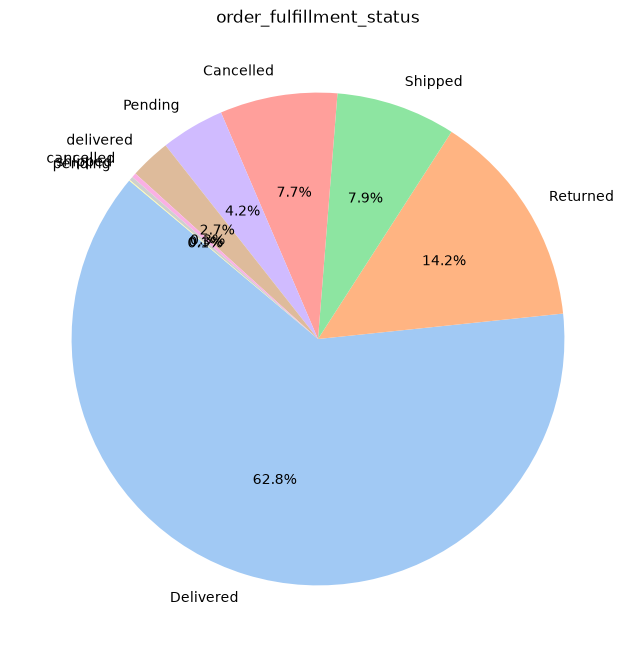

In [29]:
# order fulfillment status
order_status_count=df['order_status'].value_counts()
plt.figure(figsize=(8,8))
plt.pie(order_status_count,labels=order_status_count.index,autopct='%1.1f%%',startangle=140,colors=sb.color_palette('pastel'))
plt.title('order_fulfillment_status')
plt.show()

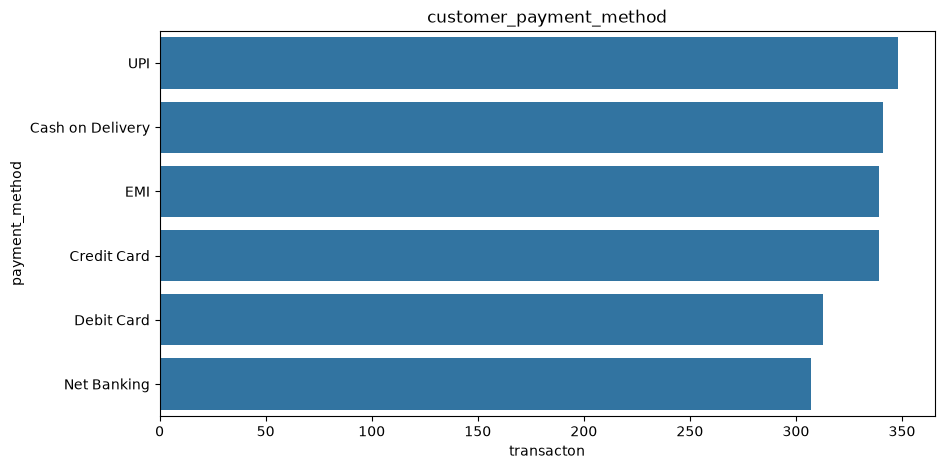

In [33]:
# Perferred payment channels
plt.figure(figsize=(10,5))
sb.countplot(y='payment_method',data=df,order=df['payment_method'].value_counts().index)
plt.title('customer_payment_method')
plt.xlabel('transacton')
plt.ylabel('payment_method')
plt.show()